## FEED FORWARD CLASSIFICATION

# Dependencies

In [ ]:
#Importing Libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns



# Reproducibilty

In [35]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Data Generation

Variables of interest:
- P is the number of patterns (clusters)
- N_s is the number of stimulus neurons (features per pattern)
- V number of variations across centers for each pattern


CENTRAL PATTERNS GENERATION - Ones with prob of 0.5


In [22]:
#generates a matrix P*N_s of binary patterns
with open("data_generation1.py", "w") as f:
    f.write("""
import numpy as np
seed = 42
import random
np.random.seed(seed)
random.seed(seed)
def generate_central_patterns(P, N_s):
    return np.random.randint(0, 2, size=(P, N_s))

""")


CENTRAL PATTERNS GENERATION - Equal proportion of ones and zeros


In [23]:
with open("data_generation2.py", "w") as f:
    f.write("""
import numpy as np

seed = 42
import random
np.random.seed(seed)
random.seed(seed)

def generate_central_patterns(P, N_s):
    central_patterns = np.zeros((P, N_s), dtype=int)
    half = N_s // 2
    for i in range(P):
        pattern = np.array([1] * half + [0] * (N_s - half))
        np.random.shuffle(pattern)
        central_patterns[i] = pattern
    return central_patterns
    """)


GENERATE VARIATIONS

patterns shape(V*P, N_s).

Check return the number of flipped values in patterns wrt central pattern. flip_prob=$\Delta S/2$


In [24]:
with open("generate_var.py", "w") as f:
    f.write("""
import numpy as np

seed = 42
import random
np.random.seed(seed)
random.seed(seed)

def generate_variations(central_patterns, labels, V, flip_prob):
    P, N_s = central_patterns.shape
    check = np.zeros(P * V)
    patterns = np.zeros((P * V, N_s))
    full_labels = np.zeros(P * V)
    for i in range(P):
        for j in range(V):
            flip_mask = np.random.rand(N_s) < flip_prob
            check[i * V + j] = np.sum(flip_mask)
            pattern = np.abs(central_patterns[i] - flip_mask.astype(int))
            patterns[i * V + j] = pattern
            full_labels[i * V + j] = labels[i]
    return patterns, full_labels, check
""")


$\Delta S =\frac{2}{N_S} \sum_{i=1}^{N_S} \mathbb{E} \left[ \left| \bar{S}_i^m - S_i^m \right| \right]$

The code ensures that the variables center and samples are converted into NumPy arrays of type float, with center also being flattened into a 1D array.

In [25]:
#we are considering a sigle pattern!
with open("delta_s.py", "w") as f:
    f.write("""
import numpy as np

def compute_delta_s(center, samples):
    center = np.asarray(center).astype(float).ravel()
    samples = np.asarray(samples).astype(float)
    if samples.shape[0] == 0:
        return 0.0
    N = center.size
    diffs = [np.sum(np.abs(sample - center)) / N for sample in samples]
    return 2 * np.mean(diffs)
""")

CHECK 1

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from importlib import reload
import delta_s
reload(delta_s)

# Use the functions defined earlier
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s

# Parameters for testing
P = 100
N_s = 100
V = 5
flip_prob = 0.1

# Generate random labels in {-1, +1}
labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 1
central_patterns= generate_central_patterns(P, N_s)
#print("Central Patterns1:\n", central_patterns)

# Generate variations
patterns, full_labels, checks = generate_variations(central_patterns, labels, V, flip_prob)
#print("\nGenerated Variations:\n", patterns)

#Check if an average of 10% of the bits are flipped
print("Average flip proportion:", np.mean(checks) / N_s)

#print Delta S
for i in range(P):
  diffs = [np.sum(np.abs(sample - central_patterns[i])) / central_patterns[i].size for sample in patterns[i*V:(i+1)*V]]
  print("diffs",diffs)
  print("mean",np.mean(diffs))
  print(2*np.mean(diffs))
  delta_s = compute_delta_s(central_patterns[i], patterns[i*V:(i+1)*V])
  print(f"ΔS for pattern {i+1}", delta_s)


Average flip proportion: 0.10054
diffs [np.float64(0.14), np.float64(0.11), np.float64(0.14), np.float64(0.11), np.float64(0.16)]
mean 0.132
0.264
ΔS for pattern 1 0.264
diffs [np.float64(0.12), np.float64(0.09), np.float64(0.1), np.float64(0.1), np.float64(0.08)]
mean 0.098
0.196
ΔS for pattern 2 0.196
diffs [np.float64(0.06), np.float64(0.15), np.float64(0.08), np.float64(0.1), np.float64(0.08)]
mean 0.094
0.188
ΔS for pattern 3 0.188
diffs [np.float64(0.06), np.float64(0.13), np.float64(0.08), np.float64(0.12), np.float64(0.1)]
mean 0.098
0.196
ΔS for pattern 4 0.196
diffs [np.float64(0.11), np.float64(0.09), np.float64(0.07), np.float64(0.05), np.float64(0.12)]
mean 0.088
0.176
ΔS for pattern 5 0.176
diffs [np.float64(0.09), np.float64(0.11), np.float64(0.07), np.float64(0.14), np.float64(0.08)]
mean 0.098
0.196
ΔS for pattern 6 0.196
diffs [np.float64(0.09), np.float64(0.06), np.float64(0.09), np.float64(0.1), np.float64(0.09)]
mean 0.086
0.172
ΔS for pattern 7 0.172
diffs [np.flo

Check in the case we have clusters with only central patterns (V=0)


In [27]:

import numpy as np
import matplotlib.pyplot as plt

# Use the functions defined earlier
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s

# Parameters for testing
P = 5
N_s = 10
V = 0

# Generate random labels in {-1, +1}
labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 1
central_patterns= generate_central_patterns(P, N_s)
print("Central Patterns1:\n", central_patterns)

# Generate variations
patterns, full_labels, checks = generate_variations(central_patterns, labels, V, flip_prob)
print("\nGenerated Variations:\n", patterns)

#20% of the bits are flipped?
#for i in range(P*V):
#  print(checks[i], end=" ")
#print()
print("Average flip proportion:", np.mean(checks) / N_s)

delta_s = compute_delta_s(central_patterns, patterns)
print(f"ΔS = {delta_s:.4f}")
flip_prob = delta_s/2
patterns.shape


Central Patterns1:
 [[0 1 0 1 1 1 1 0 1 1]
 [0 0 0 1 0 1 1 0 0 1]
 [1 0 1 0 0 0 0 1 1 0]
 [1 1 1 1 0 0 1 0 0 1]
 [0 1 0 0 1 1 0 1 1 1]]

Generated Variations:
 []
Average flip proportion: nan
ΔS = 0.0000


c:\Users\letiz\Documents\MASTER\TESI\FF_classification_2307\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\letiz\Documents\MASTER\TESI\FF_classification_2307\.venv\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


(0, 10)

CHECK 2

In [28]:
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parameters for testing
P = 5
N_s = 1000
V = 3
flip_prob = 0.3

# Generate random labels in {-1, +1}
labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 2
central_patterns = generate_central_patterns(P, N_s)
print("Central Patterns2:\n", central_patterns)

#generate variations
patterns, full_labels, checks = generate_variations(central_patterns, labels, V, flip_prob)
print("\nGenerated Variations:\n", patterns)

print("Average flip proportion:", np.mean(checks) / N_s)

Central Patterns2:
 [[0 0 0 ... 1 1 1]
 [0 1 1 ... 1 0 1]
 [1 1 0 ... 0 1 0]
 [1 1 1 ... 0 0 0]
 [0 1 1 ... 1 1 0]]

Generated Variations:
 [[0. 0. 0. ... 1. 1. 1.]
 [0. 0. 1. ... 0. 1. 1.]
 [0. 0. 0. ... 0. 1. 1.]
 ...
 [0. 1. 1. ... 1. 0. 0.]
 [0. 1. 1. ... 1. 1. 0.]
 [0. 1. 0. ... 1. 1. 0.]]
Average flip proportion: 0.3001333333333333


# Generate net inputs and threshold

The `compute_global_threshold` function computes a global threshold **T** that determines cortical sparsity across all patterns.

### Purpose:
Control the fraction of cortical neurons that are active (sparse coding) by setting an appropriate threshold for binary activation.

### Parameters:
- **`central_patterns`**: Original cluster centers, shape `(P, N_s)`
- **`noisy_patterns`**: Noisy variations, shape `(P × V, N_s)`  
- **`J`**: Synaptic weight matrix, shape `(N_c, N_s)`
- **`f`**: Desired cortical sparsity (fraction of active neurons)

In [29]:
def compute_global_threshold(central_patterns, noisy_patterns, J, f):
    """
    Computes global threshold T from all h_mj values for central and noisy patterns.

    Parameters:
        central_patterns: shape (P, N_s)
        noisy_patterns : shape (P * V, N_s)
        J: synaptic weight matrix (N_c, N_s)
        f: desired cortical sparsity

    Returns:
        T such that only top f fraction of all h_mj are above it
    """
    N_c = J.shape[0]
    h_all = []

    # Central patterns net input
    for center in central_patterns:
        h_center = J @ (center - 0.5) #shape: N_c
        h_all.append(h_center) #list of vectors

    # Noisy patterns net inputs
    for noisy in noisy_patterns:
        h_noisy = J @ (noisy - 0.5)
        h_all.append(h_noisy)

    # Flatten all h values from all neurons across all patterns
    h_all = np.concatenate(h_all)
    T = np.percentile(h_all, 100 * (1 - f)) #It sets the threshold T such that only the top f fraction of the values in h_all are greater than or equal to T
    return T

# to be deleted

In [30]:
import numpy as np
import matplotlib.pyplot as plt
seed = 42
import random
np.random.seed(seed)
random.seed(seed)


def generate_projection_matrix(N_r, N_s):
    J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
    Q = np.ones((N_r, N_s))
    J_eff = J * Q
    return J_eff

def project_and_threshold(patterns, J_eff, T):
    H = np.dot(patterns, J_eff.T)
    A_R = (H >= T).astype(int)
    return A_R, H

# Cortical patterns

In [31]:
def compute_cortical_patterns(patterns, J, T):
    """
    Compute cortical binary activity patterns from input patterns.

    Parameters:
        patterns: shape (num_patterns, N_s), binary input patterns
        J: synaptic weight matrix, shape (N_c, N_s)
        T: global threshold

    Returns:
        np.array: cortical binary patterns, shape (num_patterns, N_c)
    """
    centered_inputs = patterns - 0.5
    h = centered_inputs @ J.T     # shape: (num_patterns, N_c)
    C = (h >= T).astype(int)
    return C,h

Check cortical patterns computation

In [32]:
# Define the stimulus pattern S
S = np.array([[1, 0]])  # shape (1, 2)

#noisy variations
noisy_patterns = np.array([
    [1, 0],
    [0, 1],
    [1, 1],
    [0, 0]
])  # shape (4, 2)

# Define the synaptic weight matrix J (N_c = 4)
J = np.array([
    [1, 2],
    [-1, 0.5],
    [0.5, -0.5],
    [2, -1]
])  # shape (4, 2)

# Define the threshold
T = 0

# Compute the cortical pattern and net input h
C, h = compute_cortical_patterns(S, J, T)

# Display results
print("Net inputs h:\n", h)
print("Cortical response C:\n", C)

#Check threshould function
T_comp= compute_global_threshold(S, noisy_patterns, J, 0.5)
print("T_comp", T_comp)

Net inputs h:
 [[-0.5  -0.75  0.5   1.5 ]]
Cortical response C:
 [[0 0 1 1]]
T_comp 0.0


$\Delta C$

In [33]:
def compute_delta_c(center_cortical, noisy_corticals, f):
    """
    Compute cortical cluster size ΔC based on noisy and central cortical patterns.

    Parameters:
        central_corticals: shape (P, N_c), cortical codes for cluster centers
        noisy_corticals: shape (P * V, N_c), cortical codes for noisy variants
        full_labels: shape (P * V,), maps each noisy pattern to its cluster index
        f: sparseness level
    """

    center_cortical = np.asarray(center_cortical).astype(int).ravel()
    noisy_corticals = np.asarray(noisy_corticals).astype(int)
    Nc = center_cortical.size
    diffs = [np.sum(np.abs(sample - center_cortical)) for sample in noisy_corticals] #Hamming distance: counts how many 0/1 mismatches there are
    avg_diff = np.mean(diffs)
    epsilon = 1e-8
    delta_c = avg_diff / (2 * Nc * f * (1 - f) + epsilon)

    # Normalize by 2 * N_C * f * (1 - f)
    #delta_c = avg_diff / (2 * Nc* f * (1 - f))
    return delta_c

#Simulation and analysis of cortical size
It should approximate to  $\sqrt{ \frac{2}{\pi} \, |\log(f)| \, \Delta_S}$ if $\Delta_S$ small.
Checked.
The variability inherent in stimuli belonging to the same cluster is amplified in the cortical layer


In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Use the functions defined earlier
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
np.random.seed(42)

#parameters
P = 100    # number of clusters
V = 5       # noisy samples per cluster
N_s = 100   # stimulus neurons
N_c = 1000   # cortical neurons
f = 0.1   # sparsity level
flip_prob = 0.1  # noise level (DS ≈ 0.2)

central_patterns = generate_central_patterns(P, N_s)
labels = np.arange(P)
noisy_patterns, full_labels, check = generate_variations(central_patterns, labels, V, flip_prob)

# synaptic weights
J = np.random.normal(0, 2 / np.sqrt(N_s), size=(N_c, N_s))

# threshold
T = compute_global_threshold(central_patterns, noisy_patterns, J, f)

# cortical patterns
central_corticals,h_c = compute_cortical_patterns(central_patterns, J, T)
print(central_corticals.shape)

noisy_corticals, h_n= compute_cortical_patterns(noisy_patterns, J, T)

# delta s
delta_s = compute_delta_s(central_patterns[0], noisy_patterns[0:V])
print(f"ΔS = {delta_s:.4f}")

# delta C
delta_c = compute_delta_c(central_corticals[0], noisy_corticals[0:V], f)
print(f"ΔC = {delta_c:.4f}")

print(np.sqrt((2 / np.pi) * np.abs(np.log(f)) * delta_s))

(100, 1000)
ΔS = 0.2120
ΔC = 0.5467
0.5574627287315963


# BABADI PLOTS

#Stimulus cluster size and cortical cluster size

1.1687504639595994
1.1680710827923062
1.1634259267286495
1.1663465674843772
1.1637689194207124
1.1617660881584164
1.1597840536475286
1.1637073464617071
1.165217392084301
1.1618338393300578
DC for f=0.05: [np.float64(0.0), np.float64(0.38663157894329864), np.float64(0.5439789473626949), np.float64(0.6528210526247071), np.float64(0.7531789473604928), np.float64(0.8332210526228081), np.float64(0.8935999999905936), np.float64(0.9344842105164791), np.float64(0.973031578937126), np.float64(1.0078315789367598)]


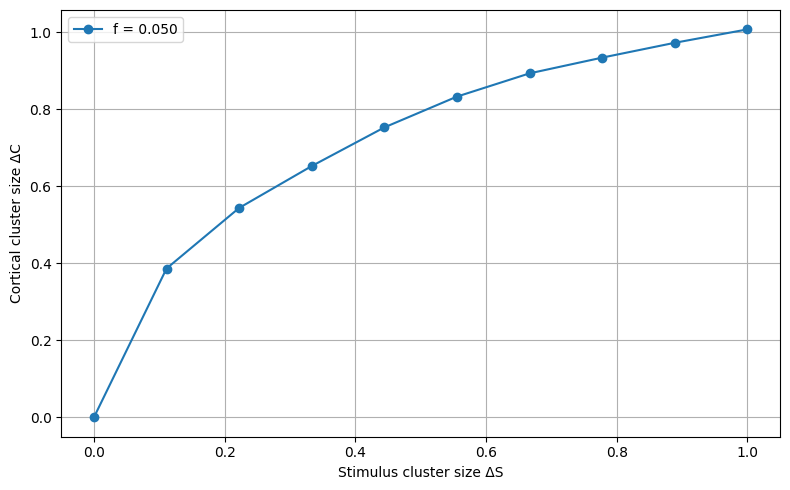

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
np.random.seed(42)

# Parameters
P = 1         # Number of clusters
V = 50        # Variations per pattern
N_s = 1000     # Input neurons
N_r = 10000     # Cortical neurons
f_values = np.array([0.001, 0.01, 0.05])  # Different sparsity levels
DS_values = np.linspace(0, 1 , 10)    # Different flip probabilities (DS ~ flip_prob)
flip_prob=DS_values/2

# Generate central patterns (same across DS)
y = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_s)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
DC=[]

plt.figure(figsize=(8, 5))
DC = []
f=0.05
for flip in flip_prob:
    noisy_patterns,_,_ = generate_variations(central_patterns, y, V, flip)
    T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
    print(T)
    central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
    noisy_corticals, _= compute_cortical_patterns(noisy_patterns, J, T)
    diff=[np.sum(np.abs(sample - central_corticals)) for sample in noisy_corticals]
    delta_c = compute_delta_c(central_corticals, noisy_corticals, f)
    DC.append(delta_c)
print(f"DC for f={f}: {DC}")
plt.plot(DS_values, DC ,marker='o',label=f"f = {f:.3f}")

# Plotting
plt.xlabel("Stimulus cluster size ΔS")
plt.ylabel("Cortical cluster size ΔC")
plt.grid(True)
plt.legend()
plt.tight_layout()

#Fraction of active neurons f and cortical cluster size $\Delta C$

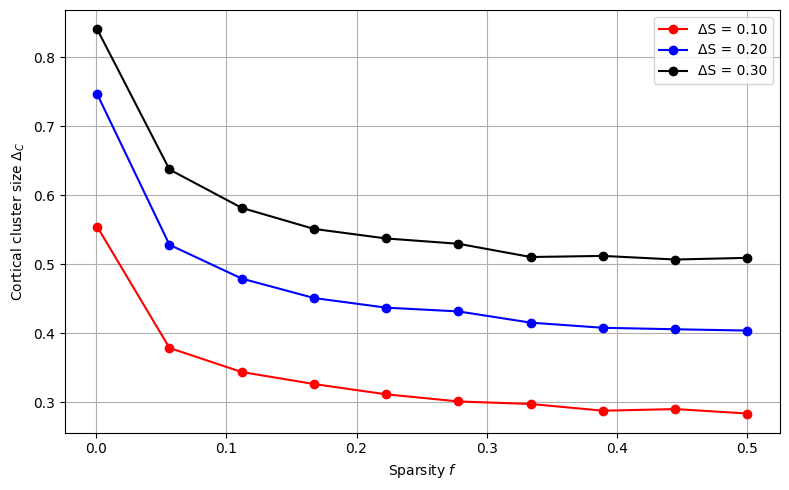

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s

np.random.seed(42)

# Parameters
P = 1               # Number of clusters
V = 50              # Variations per pattern
N_s = 1000          # Input neurons
N_r = 10000         # Cortical neurons
f_values = np.linspace(0.001, 0.5, 10)   # Sparsity values (avoid f=0)
DS_values = np.array([0.1,0.2,0.3])                               # Fixed ΔS
flip_values = DS_values / 2                          # Corresponding flip probability

# Generate data
y = np.arange(P)
central_patterns = generate_central_patterns(P, N_s)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))


plt.figure(figsize=(8, 5))
# Compute ΔC for each f
colors = ['red', 'blue', 'black']
for i, DS in enumerate(DS_values):
    flip = DS / 2
    DC = []
    for f in f_values:
        # Generate noisy patterns once
        noisy_patterns, _, _ = generate_variations(central_patterns, y, V, flip)
        T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
        noisy_corticals, _ = compute_cortical_patterns(noisy_patterns, J, T)
        delta_c = compute_delta_c(central_corticals, noisy_corticals, f)
        DC.append(delta_c)

    # Plotting
    plt.plot(f_values, DC, marker='o', color=colors[i], label=f"ΔS = {DS:.2f}")

plt.xlabel("Sparsity $f$")
plt.ylabel("Cortical cluster size $\\Delta_C$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


#Net input and probability density

PYTHON IN USO: c:\Users\letiz\Documents\MASTER\TESI\FF_classification_2307\.venv\Scripts\python.exe


C:\Users\letiz\AppData\Local\Temp\ipykernel_22656\2491929484.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


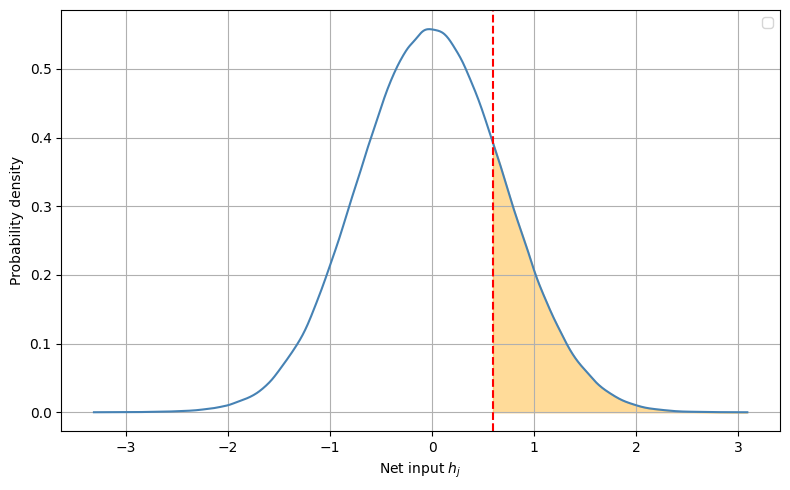

In [16]:
import sys; print("PYTHON IN USO:", sys.executable)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# Parameters
P = 1
V = 50
N_s = 1000
N_r = 10000
f = 0.2
DS = 0.1
flip_prob = DS / 2

np.random.seed(42)

# Generate data
central_patterns = generate_central_patterns(P, N_s)
y = np.arange(P)
noisy_patterns, _ ,_= generate_variations(central_patterns, y, V, flip_prob)
all_patterns = np.vstack([central_patterns] + [noisy_patterns])

# Synaptic weights
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))

# Compute h values
centered_input = all_patterns - 0.5
h = centered_input @ J.T  # shape: (num_patterns, N_r)
h_values = h.flatten()

# Compute threshold T for sparsity f
T = np.percentile(h_values, 100 * (1 - f))

# Estimate density using KDE
kde = gaussian_kde(h_values)
x_vals = np.linspace(np.min(h_values), np.max(h_values), 1000)
pdf_vals = kde(x_vals)

# Plot PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_vals, pdf_vals, color="steelblue")

# Add vertical line at threshold T
plt.axvline(T, color='red', linestyle='--')

# Shade area to the right of T (active neurons)
x_shade = x_vals[x_vals >= T]
y_shade = pdf_vals[x_vals >= T]
plt.fill_between(x_shade, y_shade, color='orange', alpha=0.4)

# Plot
plt.xlabel("Net input $h_j$")
plt.ylabel("Probability density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


1.6650617495264641
1.6630393882237555
1.6503813931090392
1.6495953997580193
1.6477852439507445
1.6443323651264807
1.6431131133483163
1.6419822862071165
1.6473960914431434
1.646867037344785
DC for f=0.01: [np.float64(0.0), np.float64(0.49929292926771246), np.float64(0.6924242423892715), np.float64(0.8021212120807009), np.float64(0.8786868686424905), np.float64(0.9476767676289051), np.float64(0.99585858580829), np.float64(1.0248484847967247), np.float64(1.0304040403519998), np.float64(1.0421212120685797)]
1.1687504639595994
1.1678711587868718
1.1673314454720765
1.160959633473058
1.1594764163365539
1.1615806135206868
1.1630668527854242
1.1611125023230189
1.163577885039007
1.1620581640395105
DC for f=0.05: [np.float64(0.0), np.float64(0.38534736841699635), np.float64(0.5499157894678955), np.float64(0.6673263157824493), np.float64(0.7587157894656977), np.float64(0.8343578947280593), np.float64(0.8879999999906526), np.float64(0.9410736842006202), np.float64(0.9793473684107437), np.float64(1.

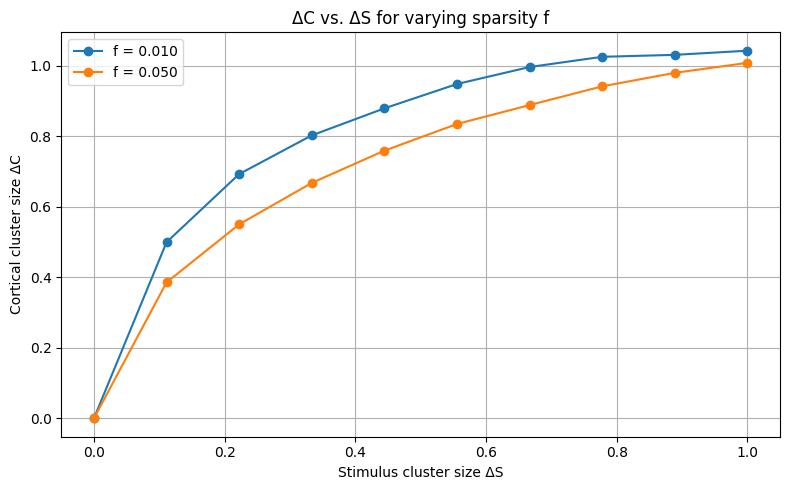

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
np.random.seed(42)

# Parameters
P = 1         # Number of clusters
V = 50        # Variations per pattern
N_s = 1000     # Input neurons
N_r = 10000     # Cortical neurons
f_values = np.array([0.01, 0.05])  # Different sparsity levels
DS_values = np.linspace(0, 1 , 10)    # Different flip probabilities (DS ~ flip_prob)
flip_prob=DS_values/2
# Generate central patterns (same across DS)
y = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_s)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
DC=[]

plt.figure(figsize=(8, 5))
for f in f_values:
  DC = []
  for flip in flip_prob:
      noisy_patterns,_,_ = generate_variations(central_patterns, y, V, flip)
      T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
      print(T)
      central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
      noisy_corticals, _= compute_cortical_patterns(noisy_patterns, J, T)
      diff=[np.sum(np.abs(sample - central_corticals)) for sample in noisy_corticals]
      delta_c = compute_delta_c(central_corticals, noisy_corticals, f)
      DC.append(delta_c)
  print(f"DC for f={f}: {DC}")
  plt.plot(DS_values, DC ,marker='o',label=f"f = {f:.3f}")

# Plotting
plt.xlabel("Stimulus cluster size ΔS")
plt.ylabel("Cortical cluster size ΔC")
plt.title("ΔC vs. ΔS for varying sparsity f")
plt.grid(True)
plt.legend()
plt.tight_layout()

# PERCEPTRON CLASSIFICATION

### 1. `train_perceptron` Function

This function implements the classic perceptron learning algorithm for binary classification.

**Key Components:**

- **Input centering**: `x_mu - f` centers cortical patterns around their mean activity
- **Weight initialization**: `W = np.random.normal(0, 1/√N_r)` uses small random weights scaled by neuron count
- **Perceptron rule**: Updates weights only when prediction is wrong

**Training Loop:**
```python
y_pred = np.sign(np.dot(x_mu - f, W))  # Make prediction
if y_mu * np.dot((x_mu-f), W) <= 0:    # Check if wrong
    W += eta * y_mu * x_mu             # Update weights
```

**Why centering matters**: Subtracting `f` (mean activity) ensures the decision boundary passes through the origin of the centered space, improving learning stability.

### 2. `test_perceptron` Function

Tests the trained perceptron on new data.

- **Output**: Classification error rate (fraction of misclassified samples)

### 3. `compute_theoretical_classification_error` Function

Computes the theoretical lower bound on classification error based on statistical mechanics theory.


In [18]:
from scipy.stats import norm
import numpy as np

#Train and test perceptron
def train_perceptron(A_R, labels, epochs, eta):
    N_samples, N_r = A_R.shape             #A_R is the matrix of ONLY central patterns
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r) #initialize the weight vector W
    f = np.mean(A_R)   #fraction of active neurons

    for epoch in range(epochs):
        errors = 0
        for mu in np.random.permutation(N_samples):
            x_mu = A_R[mu]        # input pattern, central pattern
            y_mu = labels[mu]     # target label
            y_pred = np.sign(np.dot(x_mu - f, W)) #prediction
            if y_pred == 0:
                y_pred = 1
            if y_mu * np.dot((x_mu-f), W) <= 0: #if prediction is wrong update (HERE WE SHOULD USE ONLY CENTRAL PATTERN)
                W += eta * y_mu * x_mu
                errors += 1
        if errors == 0:
            break
    return W

def test_perceptron(A_R, labels, W):
    preds = np.sign((A_R - f) @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == labels)
    return error

#Signal-to-Noise Ratio (SNR) and theoretical classification error
def compute_theoretical_classification_error(delta_C, f, P, N_C, N_S):
    alpha_C = P / N_C
    alpha_S = P / N_S
    Q = 2 * f * np.abs(np.log(f))
    SNR = (1 - delta_C)**2 / (alpha_C + alpha_S * Q**2)
    epsilon = norm.sf(np.sqrt(SNR))  # H(x) = tail of standard normal
    return epsilon


Alternative version using only central patterns

In [19]:
def train_perceptron(central_patterns, labels, f, epochs, eta):
    """
    Trains a perceptron on central cortical patterns only (Babadi-style).

    Parameters:
        central_patterns (ndarray): shape (P, N_r), cortical codes for central patterns
        labels (ndarray): shape (P,), target labels in {-1, +1}
        f (float): average activity (sparsity level)
        epochs (int): number of epochs to train
        eta (float): learning rate

    Returns:
        W (ndarray): learned weight vector (shape: N_r)
    """
    P, N_r = central_patterns.shape
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r)  # Init weights

    for epoch in range(epochs):
        errors = 0
        for mu in np.random.permutation(P):
            x_mu = central_patterns[mu] - f  # center the input
            y_mu = labels[mu]
            y_pred = np.sign(np.dot(x_mu, W))
            if y_pred == 0:
                y_pred = 1
            if y_mu * np.dot(x_mu, W) <= 0:  # misclassified
                W += eta * y_mu * x_mu
                errors += 1
        if errors == 0:
            break
    return W
def test_perceptron(test_patterns, labels, W, f):
    """
    Tests perceptron on test patterns (typically noisy cortical codes).

    Parameters:
        test_patterns (ndarray): shape (num_samples, N_r)
        labels (ndarray): true labels
        W (ndarray): trained weights
        f (float): sparsity level used for centering

    Returns:
        float: classification error
    """
    centered_test = test_patterns - f
    preds = np.sign(centered_test @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == labels)
    return error


## `run_threshold` Function

Evaluate perceptron classification performance across different sparsity levels to find the optimal threshold for cortical activity.

**Measure Actual Sparsity:**
   ```python
   f_active = np.mean(A_R)
   ```
   - Computes fraction of neurons actually active
   - This is the empirical sparsity achieved by threshold T

**Returns:**
- **`fractions_active`**: Actual sparsity levels achieved at each threshold
- **`misclassification_rates`**: Classification errors at each sparsity level

In [20]:
#Thresholding and classification
#how well the perceptron can distinguish between different stimulus patterns after projecting them to produce sparse binary cortical representations
#for a range of threshold values 𝑇

def run_threshold(all_patterns, labels, central_patterns, central_labels, N_r, N_s, epochs, eta, thresholds):
    J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
    fractions_active = []
    misclassification_rates = []

    for T in thresholds:
        A_R, _ = compute_cortical_patterns(all_patterns, J, T)  # all = central + noisy
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)

        f_active = np.mean(A_R)  # overall sparsity
        fractions_active.append(f_active)

        # Train only on central patterns
        W = train_perceptron(central_corticals, central_labels, f_active, epochs, eta)

        # Test on all patterns
        error = test_perceptron(A_R, labels, W, f_active)
        misclassification_rates.append(error)

    return fractions_active, misclassification_rates

In [21]:
#plotting
def plot_smoothed_results(fractions_active, misclassification_rates, window_size=5):
    smoothed_error = np.convolve(misclassification_rates, np.ones(window_size)/window_size, mode='valid')
    plt.figure(figsize=(8, 5))
    plt.plot(fractions_active[:len(smoothed_error)], smoothed_error * 100, marker='o',lw=2)
    plt.xlabel('Sparsity $f$ (fraction active in cortical layer)')
    plt.ylabel('% Misclassification')
    plt.title('Perceptron classification vs. sparsity $f$')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Simulation considering theoretical error

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# Parameters
P = 1000             # Number of clusters
N_C = 10000         # Cortical neurons
N_S = 1000          # Stimulus neurons
Delta_S = 0.2       # Fixed stimulus cluster size
V =50
flip_prob = Delta_S / 2  # Corresponding flip probability

# Simulate Input patterns
# Generate random labels in {-1, +1}
labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 1
central_patterns= generate_central_patterns(P, N_S)
# Generate variations
noisy_patterns, full_labels, checks = generate_variations(central_patterns, labels, V, flip_prob)
# synaptic weights
J = np.random.normal(0, 2 / np.sqrt(N_S), size=(N_C, N_S))

# Sweep over sparsity values
f_values = np.linspace(0.005, 0.1, 20)
errors = []

for f in f_values:
    T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
    # cortical patterns
    central_corticals,h_c = compute_cortical_patterns(central_patterns, J, T)
    noisy_corticals, h_n= compute_cortical_patterns(noisy_patterns, J, T)
    delta_C = compute_delta_c(central_corticals, noisy_corticals, f)
    #delta_C = np.sqrt((2 / np.pi) * np.abs(np.log(f)) * Delta_S)
    eps = compute_theoretical_classification_error(delta_C, f, P, N_C, N_S)
    errors.append(eps)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(f_values, errors,marker='o',lw=2)
plt.xlabel("Sparsity $f$")
plt.ylabel("Theoretical classification error $\\varepsilon$")
plt.title("Theoretical error vs. sparsity $f$ (ΔS = 0.2)")
plt.grid(True)
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

# 1. Simulation considering noisy patterns and deltaS_learn=0.1

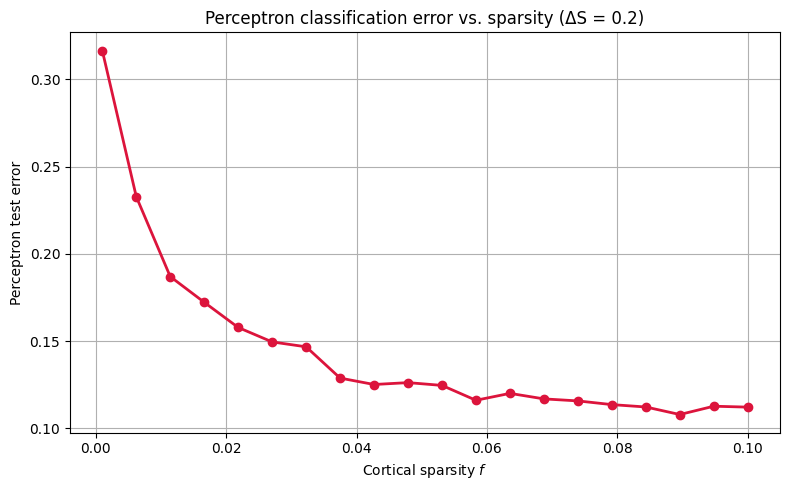

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# ----------------------------
# Parameters
# ----------------------------
P = 1000       # Number of clusters
N_S = 1000       # Sensory neurons
N_C = 10000      # Cortical neurons
V_train = 10     # Noisy patterns per cluster (training)
V_test = 25      # Noisy patterns per cluster (testing)
epochs = 100     # Perceptron training epochs
eta = 0.001      # Learning rate

deltaS_train = 0.1
deltaS_test = 0.2

flip_prob_train = deltaS_train / 2
flip_prob_test = deltaS_test / 2

f_vals = np.linspace(0.001, 0.1, 20)
errors = []

# Random seed for reproducibility
np.random.seed(42)

#Generate central patterns

labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Generate noisy training patterns (ΔS = 0.1)
noisy_train, train_labels, _ = generate_variations(central_patterns, labels, V_train, flip_prob_train)

# Generate noisy test patterns (ΔS = 0.2)
noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V_test, flip_prob_test)

# Random projection matrix J
J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))  # shape: (N_C, N_S)

# For each sparsity level f
for f in f_vals:
    # Threshold
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # cortical patterns for training
    train_cortical, _ = compute_cortical_patterns(noisy_train, J, T)

    # cortical test patterns
    test_cortical, _ = compute_cortical_patterns(noisy_test, J, T)

    # TRAINING perceptron on noisy cortical patterns
    N_samples, N_r = train_cortical.shape
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r) #initialize weight vector W randomly
    for epoch in range(epochs):
        errs = 0
        for mu in np.random.permutation(N_samples):
            x = train_cortical[mu]
            y = train_labels[mu]
            x_centered = x - f  # center
            y_pred = np.sign(np.dot(W, x_centered))
            if y_pred == 0:
                y_pred = 1
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x
                errs += 1
        if errs == 0: #Se non ci sono errori vuol dire che il perceptron classifica correttamente tutti i pattern di training.


            break

    # Test on noisy cortical patterns
    preds = np.sign((test_cortical - f) @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == test_labels) #percentage of correct predictions
    errors.append(error)

# Plotting 
plt.figure(figsize=(8, 5))
plt.plot(f_vals, errors, marker='o', lw=2, color='crimson')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Perceptron test error")
plt.title("Perceptron classification error vs. sparsity (ΔS = 0.2)")
plt.grid(True)
plt.tight_layout()
plt.show()


# 2. Implementation of perceptron following Supplemental Experimental Procedures

One pattern per class (from the paper “An epoch of training comprises the presentation of one pattern from each of the P clusters”)
deltaS_learn=0.1, eta=0,001, lenght(f_values)= 15

`train_perceptron_with_early_stopping` function

This function implements a sophisticated perceptron training algorithm that follows the Babadi paper's methodology with early stopping convergence detection.

### **Key Innovation: Training Strategy**

**"One Pattern Per Class":**
```python
for epoch in range(max_epochs):
    # One pattern per class (new noisy pattern each epoch)
    for i in range(P):
        noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
        epoch_patterns.append(noisy_pattern[0])
```

- **Each epoch**: Generates P fresh noisy patterns (one per cluster) 

1. **Threshold Computation:**

2. **Weight Updates:**
   ```python
   for x, y in zip(cortical_patterns, epoch_targets):
       x_centered = x - f
       if y * np.dot(W, x_centered) <= 0:  # misclassified
           W += eta * y * x
   ```
   - Uses standard perceptron rule but on **noisy cortical patterns**
   - Centers inputs by subtracting mean activity `f`

3. **Early Stopping Mechanism:**
   ```python
   if len(block_errors) >= 2 * block_size:
       block1 = np.mean(block_errors[-2*block_size : -block_size])
       block2 = np.mean(block_errors[-block_size:])
       if np.abs(block2 - block1) < 1e-4:
           break
   ```
   - **Monitors**: Classification accuracy on central patterns (clean evaluation)
   - **Convergence**: Stops when error plateaus over 200 epochs (2 blocks of 100)

## Explanation of `test_on_noisy_patterns` Function

This function evaluates the trained perceptron's performance on noisy test data with controlled corruption levels.

### **Test Data Generation:**
```python
noisy_test, test_labels, _ = generate_variations(
    central_patterns, labels, V=V_test, flip_prob=flip_prob_test
)
```
- **Creates**: `V_test × P` noisy test patterns
- **Noise level**: Controlled by `deltaS_test` parameter
- **Independent**: Different noise realizations from training data

### **Evaluation Process:**

1. **Cortical Projection:**
   ```python
   cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
   ```
   - Uses **same** threshold T and projection matrix J as training
   - Ensures consistent cortical representation

2. **Classification:**
   ```python
   preds = np.sign((cortical_test - f) @ W)
   preds[preds == 0] = 1
   error = 1 - np.mean(preds == test_labels)
   ```
   - **Centers** test patterns using training sparsity `f`
   - **Handles** zero predictions (assigns positive class)
   - **Returns**: Fraction of misclassified samples

### **Key Design Features:**

**Testing Scenario:**
- **Train noise**: ΔS = 0.1 (5% bit flips)
- **Test noise**: ΔS = 0.2 (10% bit flips)  
- **Challenge**: Generalize to higher noise than seen during training
- Dynamic dataset with fresh noise each epoch
- Never repeats exact same pattern

** Performance Implications**

The function is designed to answer the key research question: **"How well can a sparse cortical representation support classification when test conditions are noisier than training conditions?"**

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#
def train_perceptron_with_early_stopping(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                        
    deltaS_learn=0.1,          # ΔS for training patterns
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2 #flip probability for training patterns

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=flip_prob) #depend on deltaS_learn
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_cortical_patterns(central_patterns, J, T)
    central_cortical = central_cortical.astype(int)
    central_centered = central_cortical - f

    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs):
        # One pattern per class (new noisy pattern each epoch)
        epoch_patterns = []
        epoch_targets = []

        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_cortical_patterns(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns.astype(int)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - f
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

        # Check convergence over 2 consecutive 100-epoch blocks
        #Ogni 100 epoche controlla se l’errore medio non migliora più. Se due blocchi consecutivi hanno errore simile ferma l’allenamento.
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size]) #
            block2 = np.mean(block_errors[-block_size:]) #Calcola la media degli errori sulle ultime 100 epoche.
            if np.abs(block2 - block1) < 1e-4: #perceptron stopped decreasing
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, block_errors

def test_on_noisy_patterns(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=5):
    flip_prob_test = deltaS_test / 2

    # Generate noisy test patterns
    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    # Project to cortical space
    cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
    cortical_test = cortical_test.astype(int)

    # Predict
    preds = np.sign((cortical_test - f) @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error

Training with f = 0.001
Stopped early at epoch 302
Training with f = 0.008
Stopped early at epoch 355
Training with f = 0.015
Stopped early at epoch 251
Training with f = 0.022
Stopped early at epoch 262
Training with f = 0.029
Stopped early at epoch 222
Training with f = 0.036
Stopped early at epoch 227
Training with f = 0.043
Stopped early at epoch 331
Training with f = 0.051
Stopped early at epoch 261
Training with f = 0.058
Stopped early at epoch 246
Training with f = 0.065
Stopped early at epoch 282
Training with f = 0.072
Stopped early at epoch 234
Training with f = 0.079
Stopped early at epoch 312
Training with f = 0.086
Stopped early at epoch 280
Training with f = 0.093
Stopped early at epoch 298
Training with f = 0.100
Stopped early at epoch 241


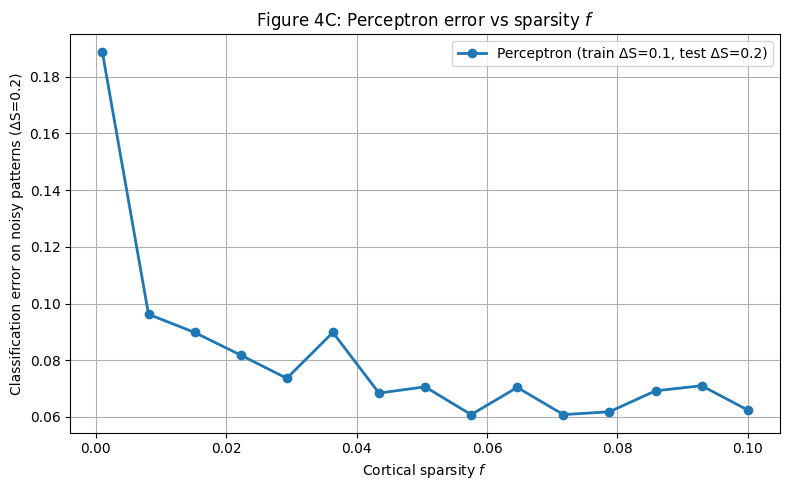

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1   # training noise
deltaS_test = 0.2    # testing noise
eta = 0.001
f_values = np.linspace(0.001, 0.1, 15)
final_errors = []

# Fixed labels and centers
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

for f in f_values:
    print(f"Training with f = {f:.3f}")

    # Random projection J
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # Use early-stopping training on ΔS = 0.1 noisy patterns
    W, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Compute threshold (reused for test too)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f) #same procedure inside the function train_perceptron_with_early_stopping

    # Test on ΔS = 0.2 noisy variants
    test_error = test_on_noisy_patterns(W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test)
    final_errors.append(test_error)

# Plotting: error vs f
plt.figure(figsize=(8, 5))
plt.plot(f_values, final_errors, marker='o', lw=2, label='Perceptron (train ΔS=0.1, test ΔS=0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Figure 4C: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 3. Analysis of perceptron and Hebbian rule

deltaS_learn=0.1, eta=0,001, lenght(f_values)= 20, N_learn=10

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
N_learn = 10
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for f in f_values:
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f) #same procedure inside the function train_perceptron_with_early_stopping

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns(W_p, central_patterns, labels, J, T, f, deltaS_test)
    perceptron_errors.append(err_p)

    # Hebbian Training 
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )#For cluster m, generate V = N_learn noisy patterns from its central pattern using a fixed flip probability of ΔS_learn / 2
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 304

--- f = 0.006 ---
Stopped early at epoch 278

--- f = 0.011 ---
Stopped early at epoch 246

--- f = 0.017 ---
Stopped early at epoch 314

--- f = 0.022 ---
Stopped early at epoch 274

--- f = 0.027 ---
Stopped early at epoch 226

--- f = 0.032 ---
Stopped early at epoch 232

--- f = 0.037 ---
Stopped early at epoch 255

--- f = 0.043 ---
Stopped early at epoch 275

--- f = 0.048 ---
Stopped early at epoch 217

--- f = 0.053 ---
Stopped early at epoch 275

--- f = 0.058 ---
Stopped early at epoch 337

--- f = 0.064 ---
Stopped early at epoch 313

--- f = 0.069 ---
Stopped early at epoch 310

--- f = 0.074 ---
Stopped early at epoch 288

--- f = 0.079 ---
Stopped early at epoch 280

--- f = 0.084 ---
Stopped early at epoch 327

--- f = 0.090 ---
Stopped early at epoch 322

--- f = 0.095 ---
Stopped early at epoch 259

--- f = 0.100 ---
Stopped early at epoch 345


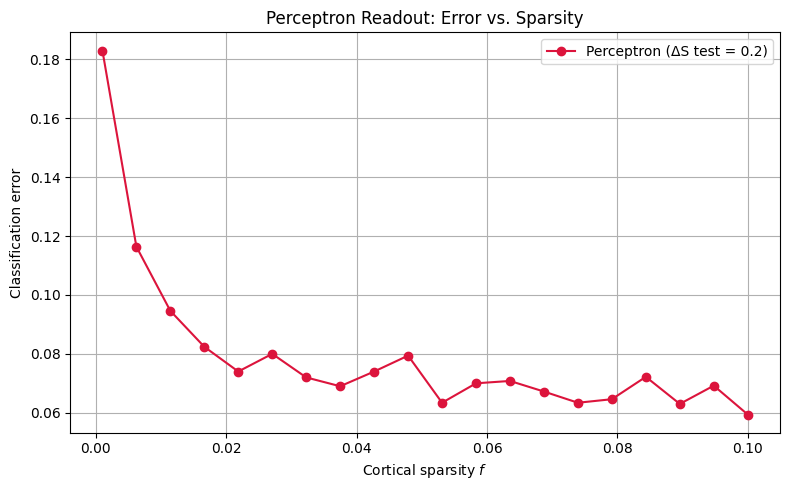

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


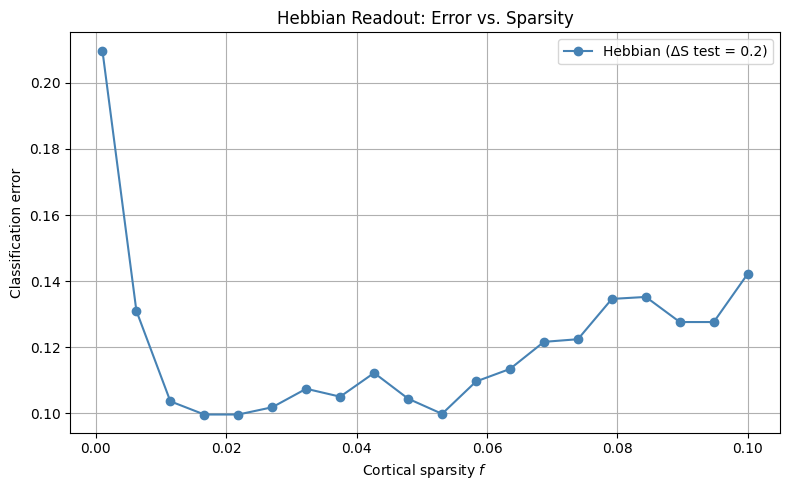

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 4. Simulation
deltaS_learn=0.1, eta=0,001, lenght(f_values)= 20, N_learn=100, V_test=10

# To be deleted
Same functions defined before

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#Training of perceptron considering early stopping
def train_perceptron_with_early_stopping(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                         # cortical sparsity
    deltaS_learn=0.1,          # learning noise
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=100, flip_prob=flip_prob)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_cortical_patterns(central_patterns, J, T)
    central_cortical = central_cortical.astype(int)
    central_centered = central_cortical - f

    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs):
        # One pattern per class (new noisy pattern each epoch)
        epoch_patterns = []
        epoch_targets = []

        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_cortical_patterns(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns.astype(int)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - f
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

#ogni 100 epoche, controllo l'errore sulle central cortical patterns
        # Check convergence over 2 consecutive 100-epoch blocks
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size])
            block2 = np.mean(block_errors[-block_size:])
            if np.abs(block2 - block1) < 1e-4:
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, block_errors

# Testing on noisy patterns:
# This function tests the perceptron on noisy patterns generated from the central patterns.
# It computes the classification error based on the learned weights W.
def test_on_noisy_patterns(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=10):
    flip_prob_test = deltaS_test / 2

    # Generate noisy test patterns
    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    # Project to cortical space
    cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
    cortical_test = cortical_test.astype(int)

    # Predict
    preds = np.sign((cortical_test - f) @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
N_learn = 100
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for i, f in enumerate(f_values):
    np.random.seed(42 + i)
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns(W_p, central_patterns, labels, J, T, f, deltaS_test)
    perceptron_errors.append(err_p)

    # === Hebbian Training ===
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 397

--- f = 0.006 ---
Stopped early at epoch 296

--- f = 0.011 ---
Stopped early at epoch 291

--- f = 0.017 ---
Stopped early at epoch 319

--- f = 0.022 ---
Stopped early at epoch 237

--- f = 0.027 ---
Stopped early at epoch 240

--- f = 0.032 ---
Stopped early at epoch 347

--- f = 0.037 ---
Stopped early at epoch 312

--- f = 0.043 ---
Stopped early at epoch 238

--- f = 0.048 ---
Stopped early at epoch 440

--- f = 0.053 ---
Stopped early at epoch 230

--- f = 0.058 ---
Stopped early at epoch 427

--- f = 0.064 ---
Stopped early at epoch 380

--- f = 0.069 ---
Stopped early at epoch 270

--- f = 0.074 ---
Stopped early at epoch 287

--- f = 0.079 ---
Stopped early at epoch 459

--- f = 0.084 ---
Stopped early at epoch 390

--- f = 0.090 ---
Stopped early at epoch 266

--- f = 0.095 ---
Stopped early at epoch 309

--- f = 0.100 ---
Stopped early at epoch 407


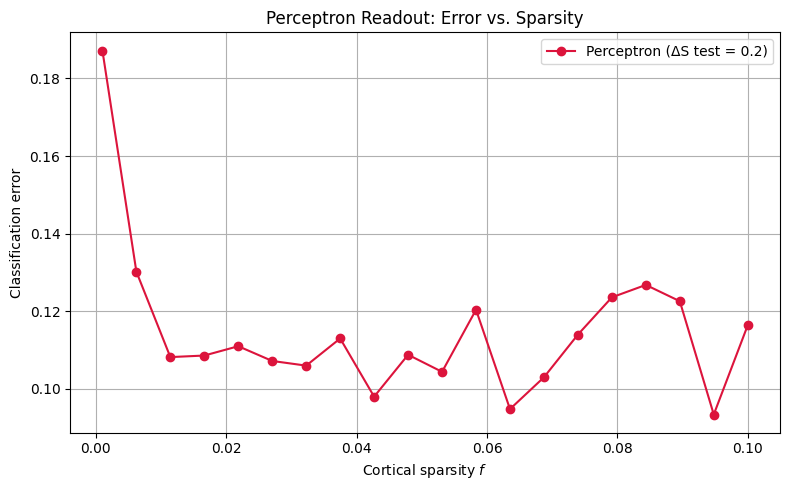

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

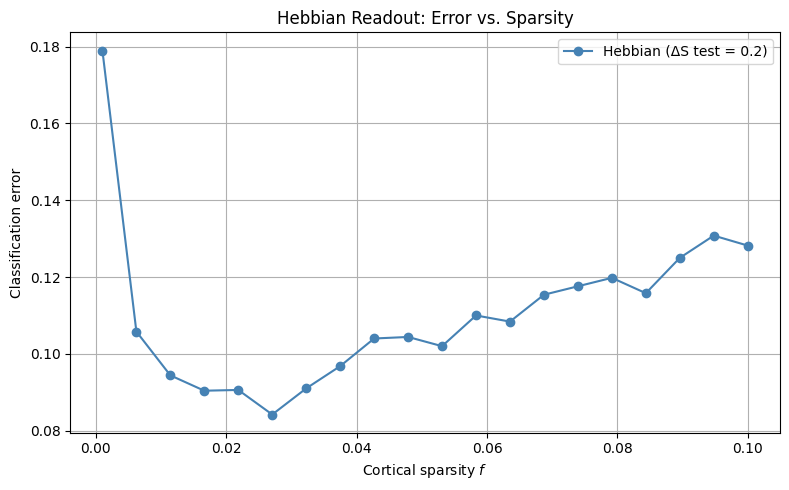

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Simulation averaging the error over multiple runs in the test
deltaS_learn=0.3

`test_on_noisy_patterns_avg` Function

Implements **statistical averaging** over multiple independent test evaluations to obtain more reliable and robust error estimates.
- **Single test runs**: Can be misleading due to random fluctuations in noise generation
- **Noise variability**: Different random noise realizations can produce different error rates
- **Statistical uncertainty**: Need reliable estimates for scientific conclusions

### **Step-by-Step Process**

**1. Multiple Independent Runs:**

**2. Fresh Noise Generation Each Run:**

**3. Consistent Evaluation Pipeline:**

**4. Statistical Averaging:**



In [ ]:
#averaging the error over multiple runs
# This function runs the test_on_noisy_patterns multiple times to average the error.
def test_on_noisy_patterns_avg(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=10, n_runs=5):
    errors = []
    for _ in range(n_runs):
        flip_prob_test = deltaS_test / 2
        noisy_test, test_labels, _ = generate_variations(
            central_patterns, labels, V=V_test, flip_prob=flip_prob_test
        )
        cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
        cortical_test = cortical_test.astype(int)
        preds = np.sign((cortical_test - f) @ W)
        preds[preds == 0] = 1
        error = 1 - np.mean(preds == test_labels)
        errors.append(error)
    return np.mean(errors)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.3
deltaS_test = 0.2
eta = 0.001
N_learn = 100
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for i, f in enumerate(f_values):
    np.random.seed(42 + i)
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns_avg(W_p, central_patterns, labels, J, T, f, deltaS_test, V_test=10, n_runs=5)
    perceptron_errors.append(err_p)

    # === Hebbian Training ===
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 420

--- f = 0.006 ---
Stopped early at epoch 278

--- f = 0.011 ---
Stopped early at epoch 305

--- f = 0.017 ---
Stopped early at epoch 351

--- f = 0.022 ---
Stopped early at epoch 322

--- f = 0.027 ---
Stopped early at epoch 411

--- f = 0.032 ---
Stopped early at epoch 308

--- f = 0.037 ---
Stopped early at epoch 232

--- f = 0.043 ---
Stopped early at epoch 349

--- f = 0.048 ---
Stopped early at epoch 487

--- f = 0.053 ---
Stopped early at epoch 468

--- f = 0.058 ---
Stopped early at epoch 261

--- f = 0.064 ---
Stopped early at epoch 357

--- f = 0.069 ---
Stopped early at epoch 328

--- f = 0.074 ---
Stopped early at epoch 432

--- f = 0.079 ---
Stopped early at epoch 330

--- f = 0.084 ---
Stopped early at epoch 330

--- f = 0.090 ---
Stopped early at epoch 545

--- f = 0.095 ---
Stopped early at epoch 345

--- f = 0.100 ---
Stopped early at epoch 290


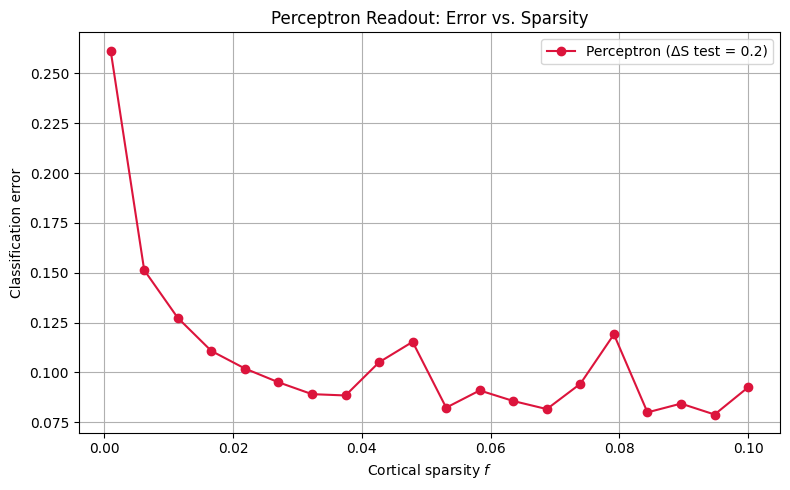

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

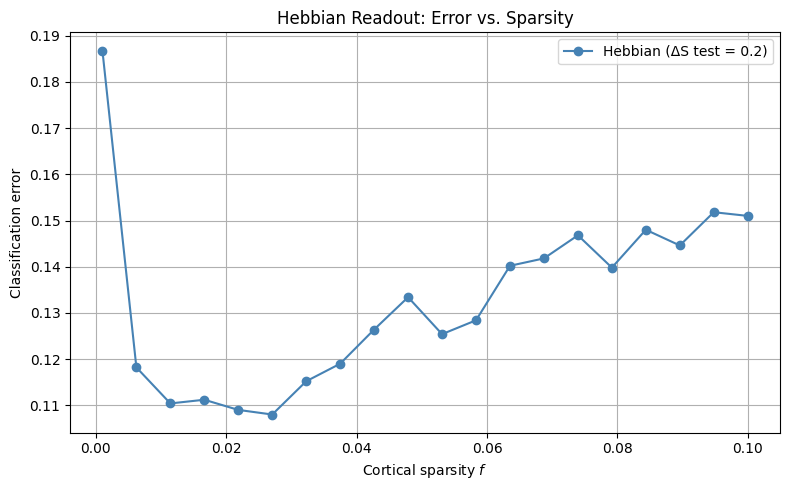

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Multiple iterations

The setup uses a **nested statistical approach** with two levels of averaging:

1. **Inner Level**: Multiple runs per sparsity value (`n_runs = 10`)
2. **Outer Level**: Multiple complete iterations of the entire experiment (`n_iterations = 5`)

- **Key Parameters**

```python
n_iterations = 5   # Number of complete experimental repetitions
n_runs = 10        # Number of runs per sparsity value within each iteration
f_values = np.linspace(0.001, 0.1, 15)  # 15 sparsity levels to test
```

- **Individual Runs (Inner Loop)**
```python
for run in range(n_runs):  # 10 runs per f value
    # Different random projection J each run
    J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))
    
    # Train perceptron with early stopping
    W, _ = train_perceptron_with_early_stopping(...)
    
    # Test on noisy patterns
    test_error = test_on_noisy_patterns(...)
    errors.append(test_error)
```

- **Iteration Statistics (Middle Loop)**
```python
for f in f_values:
    errors = []  # Collect errors from all runs
    # ... run loop ...
    mean_errors.append(np.mean(errors))    # Mean across runs
    std_errors.append(np.std(errors))      # Standard deviation across runs
```

- **Cross-Iteration Analysis (Outer Loop)**
```python
for iteration in range(1, n_iterations + 1):
    # Generate new central patterns each iteration
    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)
    
    # ... complete experiment ...
    all_iterations.append(mean_errors)
```

**Purpose**: Account for variability in:
- Central pattern generation
- Label assignment
- Overall experimental conditions



=== Iterazione 1/5 ===
Stopped early at epoch 291
Stopped early at epoch 280
Stopped early at epoch 293
Stopped early at epoch 374
Stopped early at epoch 298
Stopped early at epoch 353
Stopped early at epoch 418
Stopped early at epoch 312
Stopped early at epoch 304
Stopped early at epoch 343
Stopped early at epoch 256
Stopped early at epoch 245
Stopped early at epoch 321
Stopped early at epoch 335
Stopped early at epoch 297
Stopped early at epoch 324
Stopped early at epoch 302
Stopped early at epoch 313
Stopped early at epoch 271
Stopped early at epoch 300
Stopped early at epoch 345
Stopped early at epoch 292
Stopped early at epoch 246
Stopped early at epoch 244
Stopped early at epoch 279
Stopped early at epoch 242
Stopped early at epoch 237
Stopped early at epoch 239
Stopped early at epoch 266
Stopped early at epoch 349
Stopped early at epoch 324
Stopped early at epoch 230
Stopped early at epoch 225
Stopped early at epoch 254
Stopped early at epoch 303
Stopped early at epoch 291
Stop

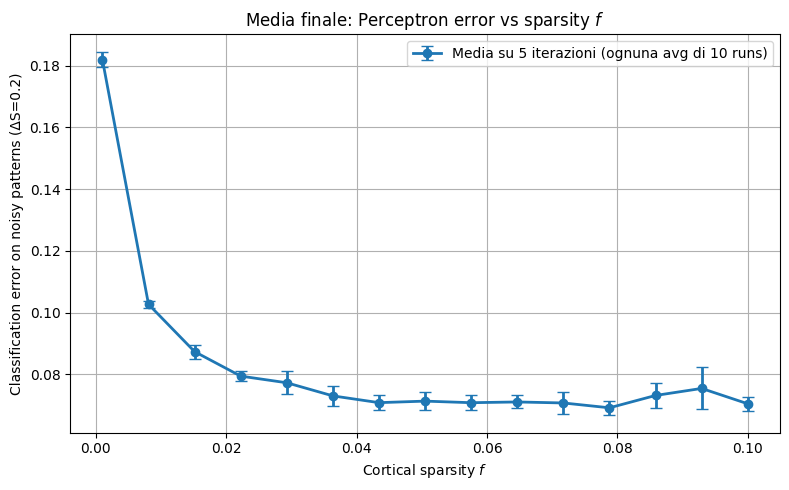

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
f_values = np.linspace(0.001, 0.1, 15)

n_iterations = 5   # quante volte ripetere l'intero esperimento
n_runs = 10        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):
            # Random projection
            J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))

            # Train
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # Threshold
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # Test
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva i risultati di questa iterazione
    all_iterations.append(mean_errors)

    # Plot singola iterazione
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (avg di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}.png", dpi=300)
    plt.close()

# Final plot: average over all iterations
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)   # media tra iterazioni
final_std = np.std(all_iterations, axis=0)     # deviazione standard tra iterazioni

plt.figure(figsize=(8, 5))

plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Media finale: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean.png", dpi=300)
plt.show()
